# Практическая работа № 11. Построение и анализ когнитивной карты

**Тема:** Низкая прибыль кофейни.

## Задание 1. Выделение факторов

Когнитивная карта показывает, какие факторы влияют друг на друга. Каждый фактор называется **концептом**.

Выделим 7 факторов. Главная проблема — низкая прибыль кофейни (**C7**). Остальные факторы могут влиять на неё напрямую или через другие факторы.

| Обозначение | Фактор |
|---|---|
| C1 | Активность в соцсетях |
| C2 | Акции и скидки |
| C3 | Уровень цен |
| C4 | Качество кофе и обслуживания |
| C5 | Посещаемость |
| C6 | Расходы кофейни |
| C7 | Прибыль |

Значения факторов дальше будем рассматривать на шкале от −1 до +1: отрицательные — ниже обычного уровня, положительные — выше.

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "DejaVu Sans"

concepts = [
    "Активность в соцсетях",
    "Акции и скидки",
    "Уровень цен",
    "Качество кофе и обслуживания",
    "Посещаемость",
    "Расходы кофейни",
    "Прибыль"
]
labels = [f"C{i + 1}" for i in range(len(concepts))]

for name, concept in zip(labels, concepts):
    print(f"{name} — {concept}")

C1 — Активность в соцсетях
C2 — Акции и скидки
C3 — Уровень цен
C4 — Качество кофе и обслуживания
C5 — Посещаемость
C6 — Расходы кофейни
C7 — Прибыль


## Задание 2. Матрица прямых влияний W

В матрице влияний строка означает причину, а столбец — следствие.

+: усиление одного фактора способствует росту другого.

-: усиление одного фактора способствует снижению другого.

0: прямое влияние не задано.

Вес связи выбираем как условную экспертную оценку в диапазоне от −1 до +1.

Для нашей кофейни предполагаем, что реклама и акции привлекают клиентов; цены могут снижать посещаемость, но повышать доход с покупки; повышение посещаемости увеличивает прибыль и расходы. Часть прибыли может направляться на продвижение.

In [ ]:
# Создаём пустую матрицу 7 × 7
n = len(concepts)
W = np.zeros((n, n))

# (причина, следствие, сила влияния); индексы начинаются с нуля
links = [
    (0, 4,  0.60),  # Соцсети -> Посещаемость
    (0, 5,  0.15),  # Соцсети -> Расходы
    (1, 4,  0.55),  # Акции -> Посещаемость
    (1, 6, -0.30),  # Акции -> Прибыль
    (2, 4, -0.50),  # Цены -> Посещаемость
    (2, 6,  0.35),  # Цены -> Прибыль
    (3, 4,  0.50),  # Качество -> Посещаемость
    (4, 6,  0.75),  # Посещаемость -> Прибыль
    (4, 5,  0.15),  # Посещаемость -> Расходы
    (4, 3, -0.12),  # Посещаемость -> Качество (нагрузка)
    (5, 6, -0.65),  # Расходы -> Прибыль
    (6, 0,  0.12)   # Прибыль -> Соцсети (вложения)
]

for source, target, weight in links:
    W[source, target] = weight

print("Матрица прямых влияний W (строка -> столбец):")
print("       " + "".join(f"{name:>7}" for name in labels))
for i, row in enumerate(W):
    print(f"{labels[i]:>7}" + "".join(f"{value:>7.2f}" for value in row))

assert W.shape == (7, 7)
assert np.all((W >= -1) & (W <= 1))
assert np.all(np.diag(W) == 0)

Матрица прямых влияний W (строка -> столбец):
            C1     C2     C3     C4     C5     C6     C7
     C1   0.00   0.00   0.00   0.00   0.60   0.15   0.00
     C2   0.00   0.00   0.00   0.00   0.55   0.00  -0.30
     C3   0.00   0.00   0.00   0.00  -0.50   0.00   0.35
     C4   0.00   0.00   0.00   0.00   0.50   0.00   0.00
     C5   0.00   0.00   0.00  -0.12   0.00   0.15   0.75
     C6   0.00   0.00   0.00   0.00   0.00   0.00  -0.65
     C7   0.12   0.00   0.00   0.00   0.00   0.00   0.00


## Задание 3. Построение когнитивной карты

Когнитивная карта — это ориентированный граф: вершины показывают факторы, стрелки — направление их влияния.

Зелёная стрелка означает положительное влияние, красная — отрицательное. Подпись возле стрелки показывает силу связи.

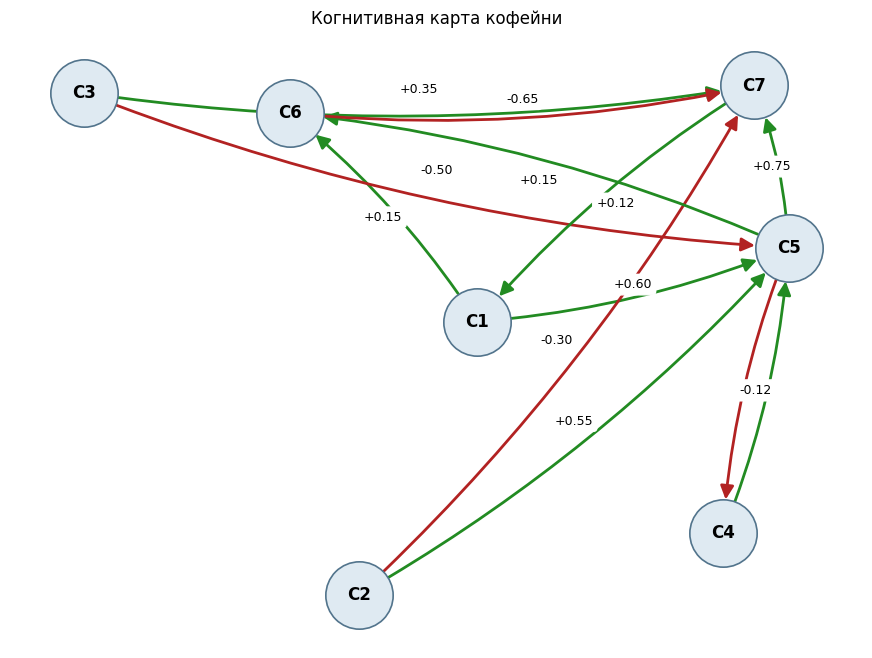

Зелёные стрелки — положительное влияние; красные — отрицательное.
C1: Активность в соцсетях
C2: Акции и скидки
C3: Уровень цен
C4: Качество кофе и обслуживания
C5: Посещаемость
C6: Расходы кофейни
C7: Прибыль


In [ ]:
G = nx.DiGraph()
G.add_nodes_from(range(n))

for i in range(n):
    for j in range(n):
        if W[i, j] != 0:
            G.add_edge(i, j, weight=W[i, j])

# Расположение вершин сохраняем одинаковым при повторном запуске
pos = nx.spring_layout(G, seed=12, k=1.2)
edge_colors = ["forestgreen" if W[i, j] > 0 else "firebrick"
               for i, j in G.edges()]
edge_labels = {(i, j): f"{W[i, j]:+.2f}" for i, j in G.edges()}

plt.figure(figsize=(11, 8))
nx.draw_networkx_nodes(G, pos, node_size=2350, node_color="#DFEAF2",
                       edgecolors="#52748C", linewidths=1.2)
nx.draw_networkx_labels(G, pos,
                        labels={i: f"C{i + 1}" for i in range(n)},
                        font_size=12, font_weight="bold")
nx.draw_networkx_edges(G, pos, edge_color=edge_colors,
                       arrows=True, arrowsize=20, node_size=2350,
                       width=2, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                             font_size=9, rotate=False)
plt.title("Когнитивная карта кофейни")
plt.axis("off")
plt.show()

print("Зелёные стрелки — положительное влияние; красные — отрицательное.")
for i, name in enumerate(concepts):
    print(f"C{i+1}: {name}")

## Задание 4. Имитационное моделирование (15 шагов)

Состояние факторов меняется из-за связей на когнитивной карте. Для расчёта используем формулу из задания и теории когнитивных карт:

$$
X(t+1)=f\left(X(t)+W^{T}X(t)\right)
$$

Здесь X(t) — значения факторов на текущем шаге, W — матрица влияний. Транспонирование W.T нужно потому, что мы записали причины в строках, а следствия в столбцах, а X храним как столбец значений. Это сумма входящих влияний.

Функция tanh удерживает значения от −1 до +1. Начальное состояние: все факторы равны 0, кроме прибыли C7 = −0.5 (прибыль ниже обычного уровня). Выполним 15 шагов.

Начальное состояние: [ 0.   0.   0.   0.   0.   0.  -0.5]
Состояние через 15 шагов:
Активность в соцсетях: -0.546
Акции и скидки: +0.000
Уровень цен: +0.000
Качество кофе и обслуживания: +0.514
Посещаемость: -0.609
Расходы кофейни: -0.705
Прибыль: -0.512


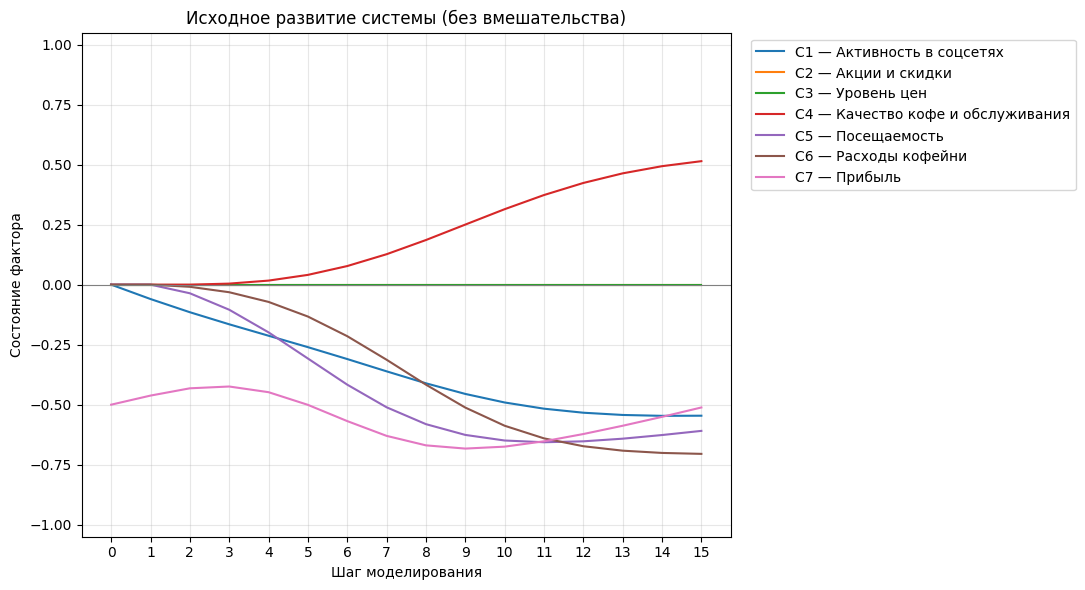

In [ ]:
def one_step(x, matrix, activation=np.tanh):
    """Один шаг: прошлое состояние + влияния других факторов."""
    return activation(x + matrix.T @ x)


def simulate(x0, matrix, steps=15, activation=np.tanh):
    """Возвращает состояния факторов с шага 0 до шага steps."""
    states = [x0.copy()]
    x = x0.copy()
    for _ in range(steps):
        x = one_step(x, matrix, activation)
        states.append(x.copy())
    return np.array(states)


X0 = np.zeros(n)
X0[6] = -0.5  # Проблема: прибыль ниже обычного уровня
steps = 15
baseline = simulate(X0, W, steps)

print("Начальное состояние:", X0)
print("Состояние через 15 шагов:")
for name, value in zip(concepts, baseline[-1]):
    print(f"{name}: {value:+.3f}")

plt.figure(figsize=(11, 6))
for i, concept in enumerate(concepts):
    plt.plot(range(steps + 1), baseline[:, i], label=f"C{i+1} — {concept}")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Шаг моделирования")
plt.ylabel("Состояние фактора")
plt.title("Исходное развитие системы (без вмешательства)")
plt.xticks(range(0, steps + 1))
plt.ylim(-1.05, 1.05)
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert baseline.shape == (16, 7)
assert np.all(np.abs(baseline) <= 1.000001)

## Задание 5. Анализ двух сценариев

Сценарий — это предположение о том, что мы изменяем один фактор, а затем наблюдаем последствия.

- **Сценарий 1:** усиливаем продвижение в соцсетях (C1 = +1).
- **Сценарий 2:** снижаем расходы (C6 = −1).

В обоих случаях изначально сохраняем проблему C7 = −0.5. Влияние задаём на начальном шаге, затем факторы изменяются по правилам карты, то есть исходное воздействие не закреплено на все 15 шагов.

Без изменений: прибыль на 15-м шаге = -0.512; первый положительный шаг = None
Продвижение: прибыль на 15-м шаге = +0.227; первый положительный шаг = 3
Снижение расходов: прибыль на 15-м шаге = +0.703; первый положительный шаг = 1


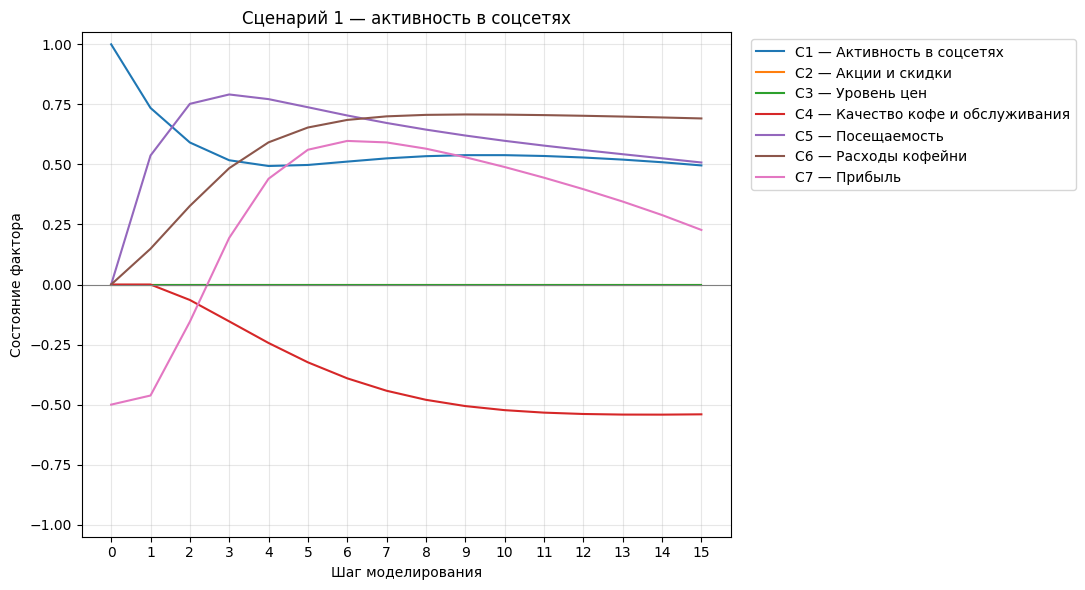

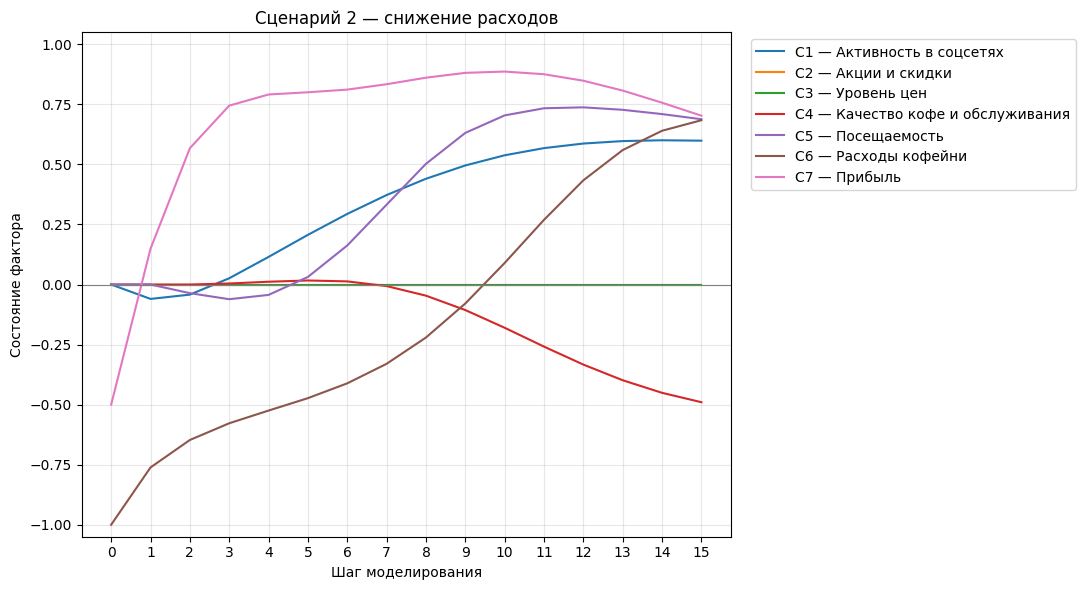

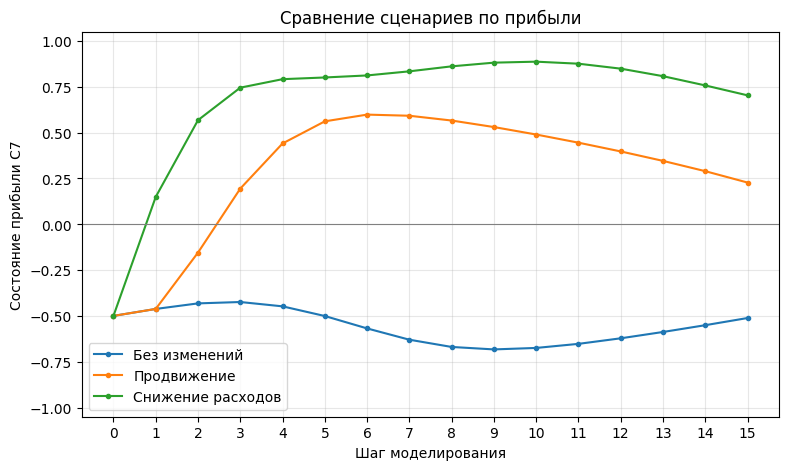

Изменение прибыли на шаге 15 относительно сценария без действий:
Продвижение: +0.739
Снижение расходов: +1.215


In [ ]:
# Сценарий 1: усиливаем продвижение
X_social = X0.copy()
X_social[0] = 1
social = simulate(X_social, W, steps)

# Сценарий 2: уменьшаем расходы
X_costs = X0.copy()
X_costs[5] = -1
costs = simulate(X_costs, W, steps)


def first_positive(states, index=6):
    """Первый шаг, на котором значение фактора стало выше нуля."""
    for step, value in enumerate(states[:, index]):
        if value > 0:
            return step
    return None


for title, states in [("Без изменений", baseline),
                      ("Продвижение", social),
                      ("Снижение расходов", costs)]:
    print(f"{title}: прибыль на 15-м шаге = {states[-1, 6]:+.3f}; "
          f"первый положительный шаг = {first_positive(states)}")

# График изменений всех факторов для каждого сценария
for title, states in [("Сценарий 1 — активность в соцсетях", social),
                      ("Сценарий 2 — снижение расходов", costs)]:
    plt.figure(figsize=(11, 6))
    for i, concept in enumerate(concepts):
        plt.plot(range(steps + 1), states[:, i], label=f"C{i+1} — {concept}")
    plt.axhline(0, color="gray", linewidth=0.8)
    plt.title(title)
    plt.xlabel("Шаг моделирования")
    plt.ylabel("Состояние фактора")
    plt.xticks(range(0, steps + 1))
    plt.ylim(-1.05, 1.05)
    plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Отдельно сравниваем прибыль на одном графике
plt.figure(figsize=(9, 5))
for title, states in [("Без изменений", baseline),
                      ("Продвижение", social),
                      ("Снижение расходов", costs)]:
    plt.plot(range(steps + 1), states[:, 6], marker="o", markersize=3,
             label=title)
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Шаг моделирования")
plt.ylabel("Состояние прибыли C7")
plt.title("Сравнение сценариев по прибыли")
plt.xticks(range(0, steps + 1))
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Изменение прибыли на шаге 15 относительно сценария без действий:")
print(f"Продвижение: {social[-1, 6] - baseline[-1, 6]:+.3f}")
print(f"Снижение расходов: {costs[-1, 6] - baseline[-1, 6]:+.3f}")

**Вывод по сценариям.** На данных экспертных оценках оба воздействия улучшают состояние прибыли относительно варианта без действий. Снижение расходов даёт более быстрый положительный эффект. Продвижение повышает посещаемость, но также увеличивает расходы, поэтому его результат развивается иначе.

## Задание 6. Анализ устойчивости

Проверим, насколько итог зависит от экспертной оценки силы связи. Для этого увеличим на 50% влияние соцсетей на посещаемость: было +0.60, станет +0.90.

Повторим первый сценарий и сравним состояние всех факторов на 15-м шаге. Если результат сильно меняется, модель чувствительна к этой оценке.

Вес C1 -> C5: 0.60 -> 0.90
Сравнение состояния на 15-м шаге:
C1 Активность в соцсетях: было +0.496, стало +0.563, разница +0.067
C2 Акции и скидки: было +0.000, стало +0.000, разница +0.000
C3 Уровень цен: было +0.000, стало +0.000, разница +0.000
C4 Качество кофе и обслуживания: было -0.540, стало -0.592, разница -0.051
C5 Посещаемость: было +0.508, стало +0.745, разница +0.236
C6 Расходы кофейни: было +0.691, стало +0.729, разница +0.037
C7 Прибыль: было +0.227, стало +0.598, разница +0.371


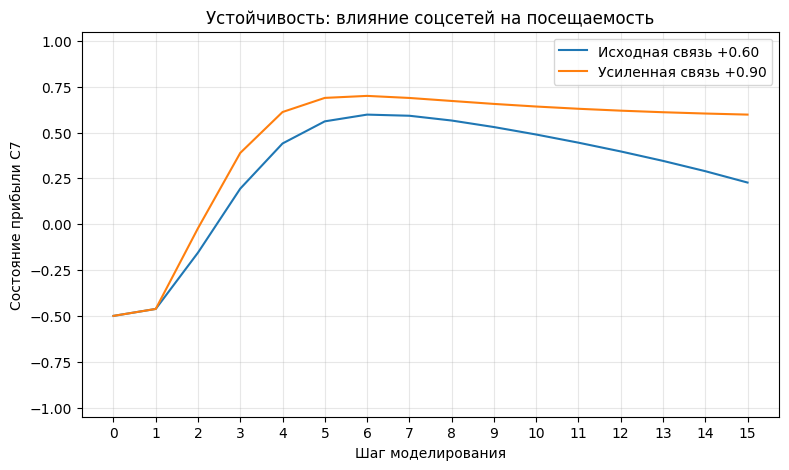

Изменение итоговой прибыли: +0.371


In [ ]:
W_changed = W.copy()
W_changed[0, 4] *= 1.5  # +50%: C1 -> C5, 0.60 -> 0.90

social_changed = simulate(X_social, W_changed, steps)
difference = social_changed[-1] - social[-1]

print(f"Вес C1 -> C5: {W[0, 4]:.2f} -> {W_changed[0, 4]:.2f}")
print("Сравнение состояния на 15-м шаге:")
for i, concept in enumerate(concepts):
    print(f"C{i+1} {concept}: было {social[-1, i]:+.3f}, "
          f"стало {social_changed[-1, i]:+.3f}, "
          f"разница {difference[i]:+.3f}")

plt.figure(figsize=(9, 5))
plt.plot(range(steps + 1), social[:, 6], label="Исходная связь +0.60")
plt.plot(range(steps + 1), social_changed[:, 6],
         label="Усиленная связь +0.90")
plt.xlabel("Шаг моделирования")
plt.ylabel("Состояние прибыли C7")
plt.title("Устойчивость: влияние соцсетей на посещаемость")
plt.xticks(range(0, steps + 1))
plt.ylim(-1.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Изменение итоговой прибыли: {difference[6]:+.3f}")
assert np.all(np.abs(W_changed) <= 1)

**Вывод по устойчивости.** Увеличение одной связи на 50% заметно изменило рассчитанное состояние прибыли на 15-м шаге. Значит, в этом сценарии итог чувствителен к оценке влияния соцсетей на посещаемость. Поэтому экспертные веса следует задавать внимательно.

## Дополнительное задание 1. Косвенные и общие влияния

Матрица W показывает прямые связи (одна стрелка). Матрица W² показывает влияния через два последовательных перехода, а W³ — через три.

Чтобы увидеть суммарные прямые и косвенные влияния на путях длиной от 1 до 3, сложим W + W² + W³.

In [ ]:
W2 = np.linalg.matrix_power(W, 2)
W3 = np.linalg.matrix_power(W, 3)
W_total = W + W2 + W3

print("Косвенные влияния через 2 связи (W²):")
print(np.round(W2, 3))
print("\nКосвенные влияния через 3 связи (W³):")
print(np.round(W3, 3))
print("\nОбщие влияния по путям длиной 1–3 (W + W² + W³):")
print(np.round(W_total, 3))

print("\nВлияние соцсетей C1 на прибыль C7:")
print(f"Прямое: {W[0, 6]:+.3f}")
print(f"Через 2 связи: {W2[0, 6]:+.3f}")
print(f"Через 3 связи: {W3[0, 6]:+.3f}")
print(f"Сумма: {W_total[0, 6]:+.3f}")

Косвенные влияния через 2 связи (W²):
[[ 0.     0.     0.    -0.072  0.     0.09   0.352]
 [-0.036  0.     0.    -0.066  0.     0.082  0.413]
 [ 0.042  0.     0.     0.06   0.    -0.075 -0.375]
 [ 0.     0.     0.    -0.06   0.     0.075  0.375]
 [ 0.09   0.     0.     0.    -0.06   0.    -0.098]
 [-0.078  0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.072  0.018  0.   ]]

Косвенные влияния через 3 связи (W³):
[[ 0.042  0.     0.     0.    -0.036  0.    -0.058]
 [ 0.05   0.     0.     0.    -0.055 -0.005 -0.054]
 [-0.045  0.     0.     0.     0.055  0.006  0.049]
 [ 0.045  0.     0.     0.    -0.03   0.    -0.049]
 [-0.012  0.     0.     0.007  0.054  0.005 -0.045]
 [ 0.     0.     0.     0.    -0.047 -0.012  0.   ]
 [ 0.     0.     0.    -0.009  0.     0.011  0.042]]

Общие влияния по путям длиной 1–3 (W + W² + W³):
[[ 0.042  0.     0.    -0.072  0.564  0.24   0.294]
 [ 0.014  0.     0.    -0.066  0.495  0.077  0.059]
 [-0.003  0.     0.     0.06  -0.445 -0

**Вывод.** Прямой связи между соцсетями и прибылью нет (0), но есть косвенные пути, например **соцсети → посещаемость → прибыль** и **соцсети → расходы → прибыль**. Поэтому итоговое косвенное влияние может быть ненулевым.

## Дополнительное задание 2. Сравнение функций активации

Функция активации ограничивает значения факторов. Сравним два простых способа:

- tanh — плавно приближает значения к −1 и +1;
- clip — просто обрезает значения, выходящие за границы от −1 до +1.

Возьмём один и тот же сценарий продвижения и сравним состояние прибыли.

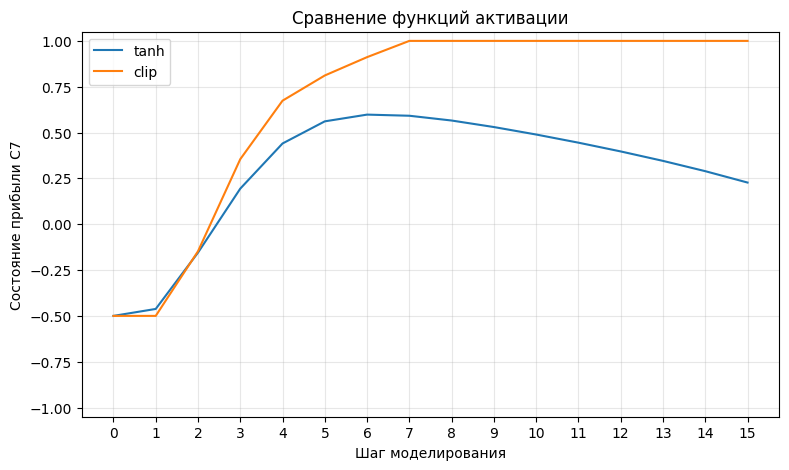

Прибыль на 15-м шаге с tanh: +0.227
Прибыль на 15-м шаге с clip: +1.000


In [ ]:
def clip_activation(x):
    return np.clip(x, -1, 1)

social_tanh = simulate(X_social, W, steps, activation=np.tanh)
social_clip = simulate(X_social, W, steps, activation=clip_activation)

plt.figure(figsize=(9, 5))
plt.plot(range(steps + 1), social_tanh[:, 6], label="tanh")
plt.plot(range(steps + 1), social_clip[:, 6], label="clip")
plt.xlabel("Шаг моделирования")
plt.ylabel("Состояние прибыли C7")
plt.title("Сравнение функций активации")
plt.xticks(range(0, steps + 1))
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Прибыль на 15-м шаге с tanh: {social_tanh[-1, 6]:+.3f}")
print(f"Прибыль на 15-м шаге с clip: {social_clip[-1, 6]:+.3f}")

**Вывод.** Выбор функции активации влияет на изменение факторов. При clip значения могут быстро достигать границы ±1, а при tanh изменения происходят более плавно. Поэтому результаты зависят не только от весов связей, но и от выбранной функции активации.

## Дополнительное задание 3. Поиск петель обратной связи

Петля обратной связи — это цепочка влияний, которая возвращается к исходному фактору. Например, увеличение посещаемости влияет на прибыль, а прибыль — на продвижение, которое снова влияет на посещаемость.

Поиск выполним автоматически с помощью networkx.simple_cycles().

In [ ]:
cycles = list(nx.simple_cycles(G))

print(f"Найдено циклов: {len(cycles)}")
for cycle in sorted(cycles, key=lambda x: (len(x), x)):
    path = cycle + [cycle[0]]
    product = 1
    for i, j in zip(path[:-1], path[1:]):
        product *= W[i, j]
    cycle_type = "положительная" if product > 0 else "отрицательная"
    text = " -> ".join(f"C{i + 1}" for i in path)
    print(f"{text}: {cycle_type} обратная связь")

assert len(cycles) > 0

Найдено циклов: 4
C4 -> C5 -> C4: отрицательная обратная связь
C1 -> C5 -> C7 -> C1: положительная обратная связь
C1 -> C6 -> C7 -> C1: отрицательная обратная связь
C1 -> C5 -> C6 -> C7 -> C1: отрицательная обратная связь


**Вывод.** В модели есть несколько циклов обратной связи. Положительная петля может усиливать начальные изменения, а отрицательная — сдерживать их. Например, рост посещаемости способен увеличить нагрузку и ухудшить обслуживание, что затем ограничивает посещаемость.

## Вывод

Я построила когнитивную карту низкой прибыли кофейни из семи факторов, задала экспертные веса связей и провела 15 шагов моделирования. Сравнила два решения: усиление продвижения в соцсетях и снижение расходов. На условных оценках оба сценария дали улучшение прибыли по сравнению с отсутствием действий, но снижение расходов оказалось эффективнее по результату на 15-м шаге. Также проверила чувствительность к весам, рассчитала косвенные влияния, сравнила функции активации и нашла циклы обратной связи.